# 07 - Closed frequent itemsets with the COFI-tree algorithm

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)
def show(f, w=900): display(Image(filename=str(ROOT / 'outputs' / 'plots' / f), width=w))

In [2]:
from src.cofi.cofi import cofi_mine
from src.cofi.run_cofi import LECTURE11_DB
res = cofi_mine(LECTURE11_DB, min_count=3)
print('Lecture 11 closed sets:', [sorted(x) for x in res.closed])

Lecture 11 closed sets: [['A', 'C'], ['B', 'E'], ['B', 'C', 'E'], ['C']]


In [3]:
from src.cofi import run_cofi
s = run_cofi.run()
s['validation']

2026-11-21 13:06:04,522 | cofi | INFO | PHASE 9 - COFI started


2026-11-21 13:06:36,344 | cofi | INFO | PHASE 9 complete: frequent=310 closed=293 maximal=127 validation={'V1_lecture11_example': True, 'V2_bruteforce_random': True, 'V3_movie_cross_check': {'cofi_frequent': 310, 'apriori_frequent': 310, 'mlxtend_fpgrowth_frequent': 310, 'identical_to_apriori': True, 'identical_to_mlxtend_fpgrowth': True}, 'V4_V5_closed_checks': True}


{'V1_lecture11_example': {'closed_found': [('A', 'C'),
   ('B', 'C', 'E'),
   ('B', 'E'),
   ('C',)],
  'expected': [('A', 'C'), ('B', 'C', 'E'), ('B', 'E'), ('C',)],
  'passed': True},
 'V2_bruteforce_random': {'databases': 30,
  'frequent_identical': 30,
  'closed_identical': 30,
  'passed': True},
 'V3_movie_cross_check': {'cofi_frequent': 310,
  'apriori_frequent': 310,
  'mlxtend_fpgrowth_frequent': 310,
  'identical_to_apriori': True,
  'identical_to_mlxtend_fpgrowth': True},
 'V4_V5_closed_checks': {'closed_checked': 293,
  'wrong_support': 0,
  'infrequent': 0,
  'not_closed_by_closure_operator': 0,
  'frequent_without_closed_cover': 0,
  'passed': True}}

In [4]:
print(open('outputs/cofi/cofi_execution_summary.txt', encoding='utf-8').read())

COFI CLOSED FREQUENT ITEMSET MINING - EXECUTION SUMMARY
Transactions             : 11408
Minimum support          : 0.02 (count >= 229)
Frequent items (COFI-trees built): 44
Global FP-tree nodes     : 9073
Largest single COFI-tree : 175 nodes (only one tree in memory at a time)
Frequent itemsets        : 310
Closed frequent itemsets : 293
Maximal frequent itemsets: 127
Compression (frequent/closed): 1.06x
Time: FP-tree 0.7179s, COFI mining 0.1624s, closedness check 0.0452s, total 0.9258s
Peak Python heap during mining: 2.11 MB

VALIDATION
----------------------------------------------------------------
V1_lecture11_example: {"closed_found": [["A", "C"], ["B", "C", "E"], ["B", "E"], ["C"]], "expected": [["A", "C"], ["B", "C", "E"], ["B", "E"], ["C"]], "passed": true}
V2_bruteforce_random: {"databases": 30, "frequent_identical": 30, "closed_identical": 30, "passed": true}
V3_movie_cross_check: {"cofi_frequent": 310, "apriori_frequent": 310, "mlxtend_fpgrowth_frequent": 310, "identical_to

In [5]:
pd.read_csv('outputs/cofi/closed_frequent_itemsets.csv').head(20)

,itemset,support_count,support_pct,n_items,closed,maximal
0,"color=bw, era=Post-studio (1949-66), format=TV, genre=Suspense/thriller, studio=Shamle...",278,2.437,5,True,True
1,"cast 3-5, color=color, dir_country=USA, era=Modern (1981-99)",441,3.866,4,True,True
2,"cast 6-9, color=bw, dir_country=USA, era=Classical studio (1928-48)",376,3.296,4,True,True
3,"color=bw, era=Post-studio (1949-66), genre=Suspense/thriller, studio=Shamley (Hitchcoc...",353,3.094,4,True,False
4,"cast 6-9, color=color, dir_country=USA, era=Modern (1981-99)",344,3.015,4,True,True
5,"cast 3-5, color=color, dir_country=USA, era=New Hollywood (1967-80)",342,2.998,4,True,True
6,"cast 3-5, color=color, era=Modern (1981-99), genre=Drama",257,2.253,4,True,True
7,"color=bw, dir_country=USA, era=Classical studio (1928-48), genre=Comedy",248,2.174,4,True,True
8,"cast 6-9, color=color, dir_country=USA, era=New Hollywood (1967-80)",244,2.139,4,True,True
9,"color=color, dir_country=USA, era=Modern (1981-99), genre=Comedy",236,2.069,4,True,True


In [6]:
pd.read_csv('outputs/cofi/support_comparison.csv')

,min_support,min_count,frequent_itemsets,closed_itemsets,maximal_itemsets,compression_ratio,cofi_time_s,apriori_time_s,fp_tree_nodes,largest_cofi_tree_nodes,identical_to_apriori
0,0.005,58,1744,1552,591,1.124,0.6240,0.3755,10636,629,True
1,0.010,115,758,686,272,1.105,0.2036,0.4532,10276,376,True
2,0.020,229,310,293,127,1.058,0.3143,0.4002,9073,175,True
3,0.030,343,165,158,75,1.044,0.0897,0.3005,7731,125,True
4,0.050,571,80,80,37,1.000,0.1486,0.3016,3816,23,True
5,0.100,1141,33,33,14,1.000,0.1361,0.1912,667,7,True


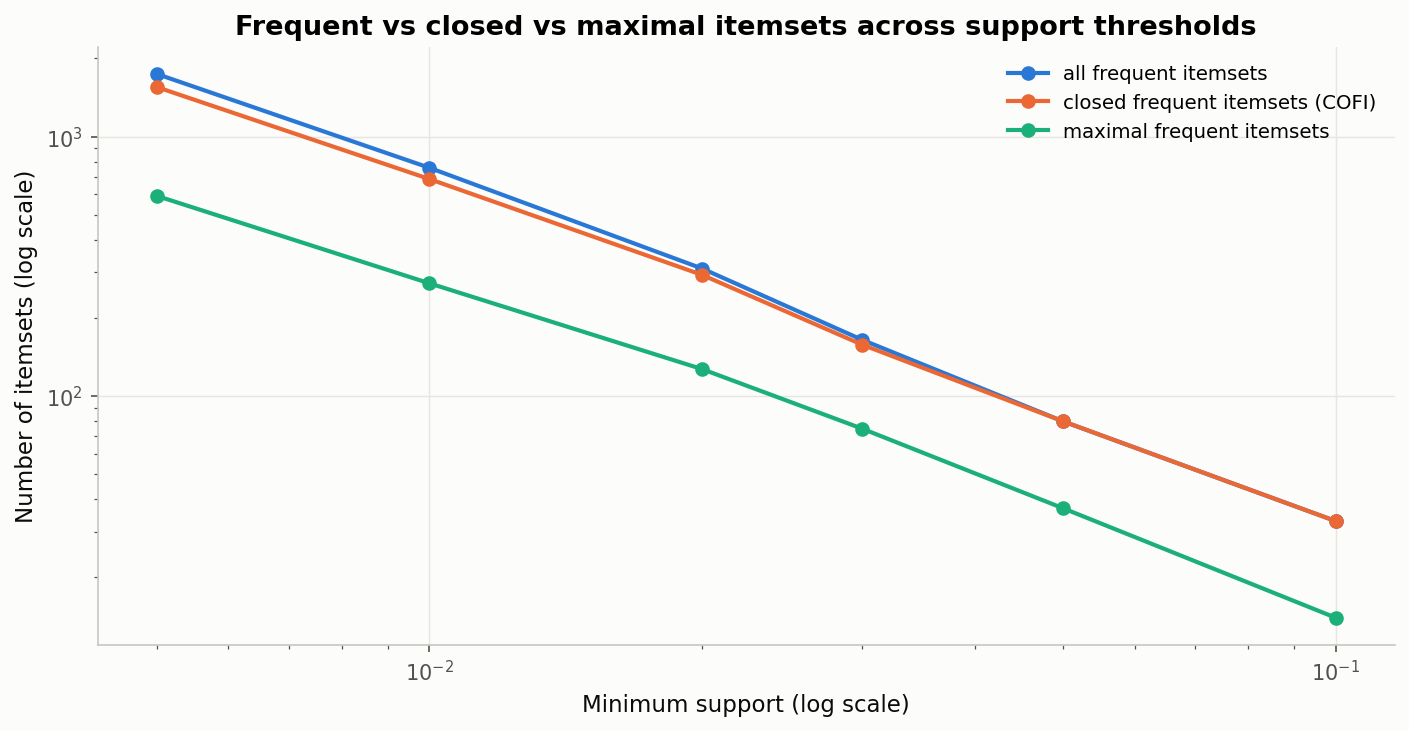

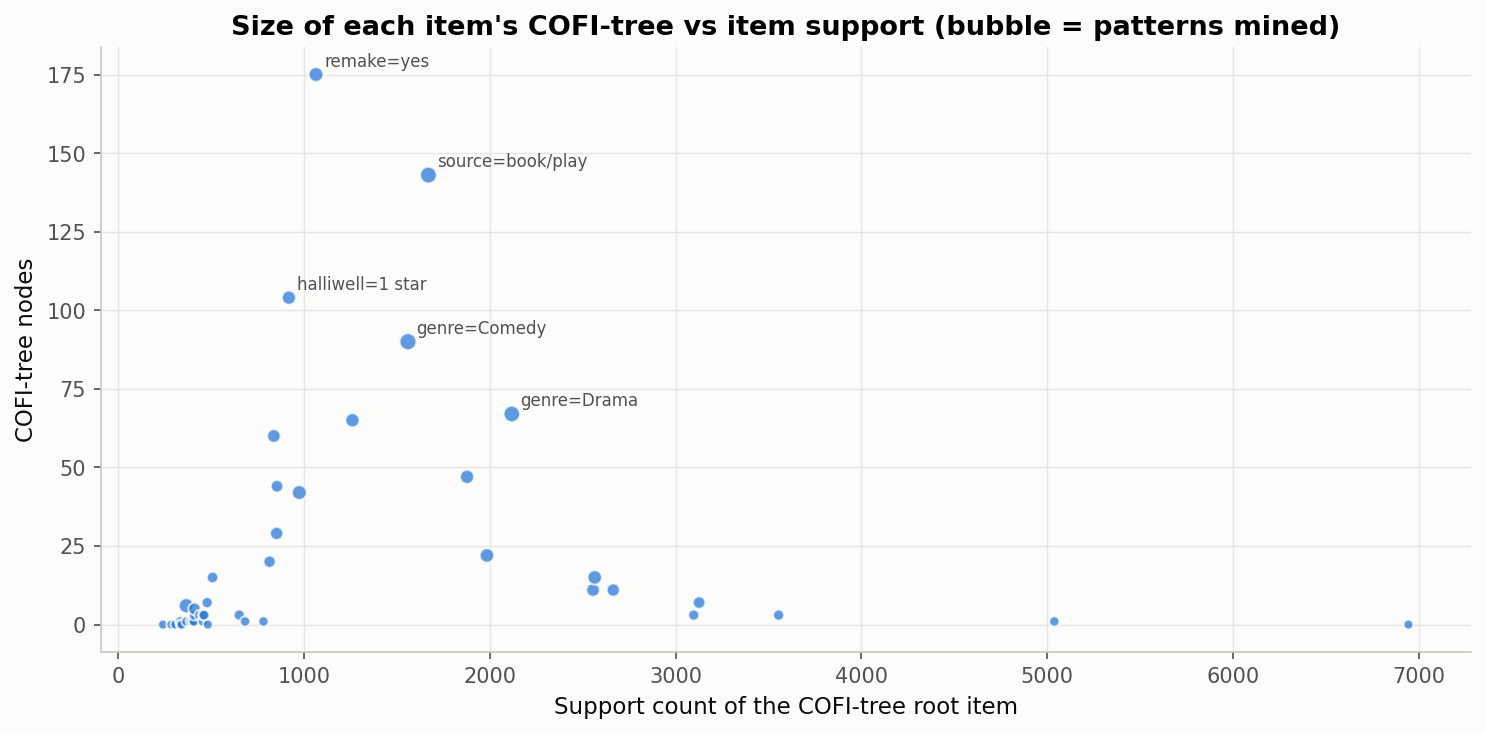

In [7]:
for f in ['21_cofi_frequent_closed_maximal.png','22_cofi_tree_sizes.png']: show(f)